<a href="https://colab.research.google.com/github/eduardozurek/ia/blob/main/_007_aprendizaje_supervisado/_008_clasificadores_bayesianos/09b_Gaussiano.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Ejemplo - Gaussiano - Clasificador Bayesiano Ingenuo - Naïve Bayes Classifier**


El ejemplo lo basaremos en datos simulados que representan\
una población de personas de género masculino\
niños y adultos, y se tienen dos características de ellos: estatura y peso

Text(0, 0.5, 'Peso en kilogramos')

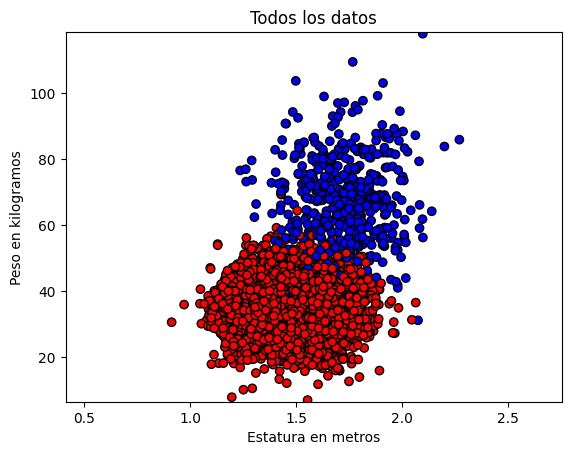

In [ ]:
from sklearn.datasets import make_blobs
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

X, y = make_blobs(n_samples=[5000,500],
                  n_features = 2,
                  centers=[[1.49,35],[1.72,67]],
                  cluster_std = [[0.15,7],[0.18,15]],
                  random_state=1970)

x_min, x_max = X[:, 0].min() - .5, X[:, 0].max() + .5
y_min, y_max = X[:, 1].min() - .5, X[:, 1].max() + .5
h = 0.02  # step size in the mesh
xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                      np.arange(y_min, y_max, h))

# just plot the dataset first
cm = plt.cm.RdBu
cm_bright = ListedColormap(['#FF0000', '#0000FF'])
ax = plt.figure()
plt.title("Todos los datos")
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=cm_bright,
            edgecolors='k')
plt.xlim(xx.min(), xx.max())
plt.ylim(yy.min(), yy.max())
plt.xlabel("Estatura en metros")
plt.ylabel("Peso en kilogramos")

Ahora creamos los datos de prueba y entrenamiento

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = \
    train_test_split(X, y, test_size=0.33, random_state=1970)

In [ ]:
from sklearn.naive_bayes import GaussianNB
GaussNB = GaussianNB() #priors=[0.5,0.5])
GaussNB.fit(X_train,y_train)
y_esperado = y_test
y_predicho = GaussNB.predict(X_test)

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score, precision_score
print(accuracy_score(y_esperado,y_predicho))
print(recall_score(y_esperado,y_predicho))
print(precision_score(y_esperado,y_predicho))
print(confusion_matrix(y_esperado,y_predicho))

0.9823691460055096
0.8490566037735849
0.9440559440559441
[[1648    8]
 [  24  135]]


Como se puede ver, el sistema es capaz de clasificar\
correctamente mas del 95% de los datos de prueba

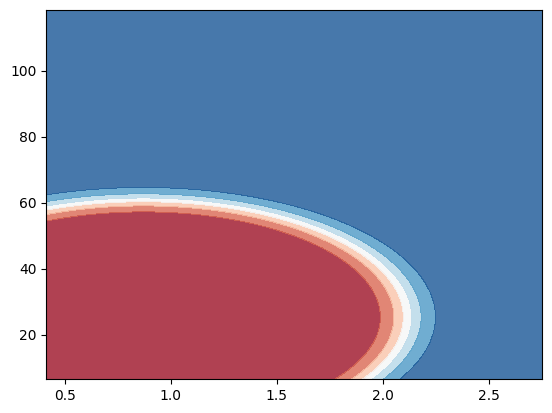

In [ ]:
Z = GaussNB.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1]
# Put the result into a color plot
Z = Z.reshape(xx.shape)
plt.contourf(xx, yy, Z, cmap=cm, alpha=.8)

Y esto es lo que el sistema sabe\
la elipse roja representa los niños\
el resto lo considera adultos

0.9823691460055096
0.8490566037735849
0.9440559440559441
[[1648    8]
 [  24  135]]


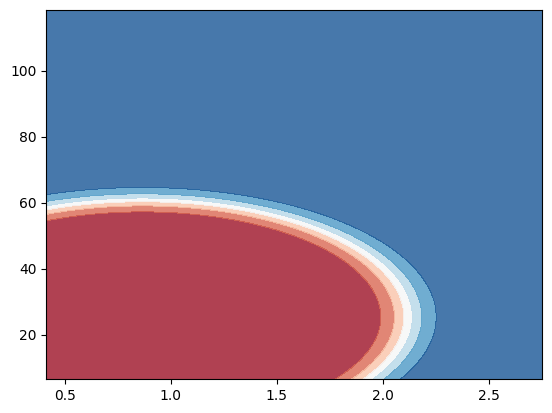

In [ ]:
from sklearn.naive_bayes import GaussianNB
GaussNB = GaussianNB(var_smoothing=1e-6) #priors=[0.5,0.5])
GaussNB.fit(X_train,y_train)
y_esperado = y_test
y_predicho = GaussNB.predict(X_test)
print(accuracy_score(y_esperado,y_predicho))
print(recall_score(y_esperado,y_predicho))
print(precision_score(y_esperado,y_predicho))
print(confusion_matrix(y_esperado,y_predicho))
Z = GaussNB.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1]
# Put the result into a color plot
Z = Z.reshape(xx.shape)
plt.contourf(xx, yy, Z, cmap=cm, alpha=.8)